<a href="https://colab.research.google.com/github/Andressuz2460/Optativa_II_TDS/blob/main/Regresion_Lineal_Base_Incorporada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión lineal múltiple — curso completo con interpretación de resultados

**Optativa II - Universidad Católica de Pereira - Tecnología en Desarrollo de Software**

**Guía· Google Colab y VS Code · Base de datos incorporada · 400 estudiantes ficticios**

**Objetivo.** Aprender a generar los datos, explorarlos, construir una regresión lineal múltiple, interpretar **cada tabla, indicador, coeficiente y gráfica**, y decidir con argumentos si el modelo predice razonablemente bien.

✅ **Un solo archivo:** no se necesita cargar un CSV, montar Google Drive, usar internet, instalar complementos ni aportar archivos externos. Ejecuta las celdas **de arriba hacia abajo** con «Entorno de ejecución → Ejecutar todas». La base se genera dentro del notebook mediante un generador reproducible.

> **Advertencia científica:** estos 400 registros son totalmente **sintéticos**. Las asociaciones han sido diseñadas deliberadamente para practicar; no son evidencia sobre estudiantes reales. La semilla fija permite obtener los mismos resultados en ejecuciones repetidas con versiones compatibles de las librerías, aunque diferencias de versiones pueden alterar cifras mínimamente.

**Cómo leer esta guía:** después de cada salida, encontrarás instrucciones docentes y en varias celdas un comentario **automático basado en el valor realmente calculado**, evitando depender de números de otro archivo.

## 1. Preparar herramientas

- **NumPy (`np`)**: crea valores aleatorios y realiza cálculos numéricos.
- **pandas (`pd`)**: organiza datos y tablas.
- **Matplotlib (`plt`)**: dibuja gráficos.
- **scikit-learn**: divide los datos, aprende la ecuación y calcula métricas.

**Qué debes decir en clase:** importar una biblioteca no entrena un modelo. Solo pone a disposición funciones para pasos posteriores. `random_state` y la semilla hacen reproducible el ejercicio; 42 no es una medida de calidad.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_validate

SEMILLA = 42
pd.set_option("display.max_columns", 20)
print("Bibliotecas importadas. Semilla de reproducibilidad:", SEMILLA)

Bibliotecas importadas. Semilla de reproducibilidad: 42


## 2. Construir la base de datos **dentro** del notebook

**¿Cómo funciona?** Simularemos **400 estudiantes** con cinco columnas: cuatro explicativas y la nota final. Fijaremos límites razonables para las variables. La nota final se calculará usando una fórmula intencionalmente lineal más un componente aleatorio, de modo que la clase pueda aprender a recuperar esa relación.

**Parámetros de simulación — no son hechos empíricos:**

\[
\text{nota simulada}=-0.17+0.62(\text{promedio})+0.055(\text{horas})+0.011(\text{asistencia})-0.22(\text{trabaja})+\epsilon
\]

La letra ε es ruido aleatorio; en este ejemplo sigue una distribución normal con desviación estándar de 0,18. Después acotamos la nota al intervalo [0, 5] y redondeamos a dos decimales. Esta operación puede modificar ligeramente las relaciones lineales.

**Importante:** no debes adjuntar CSV. La tabla `datos` queda creada en memoria por la celda siguiente.

In [ ]:
# Reproducibilidad: el generador produce la misma secuencia para esta semilla.
rng = np.random.default_rng(SEMILLA)
n = 400

# Cuatro características simuladas, sin identificar a personas reales.
promedio = np.round(np.clip(rng.normal(3.60, 0.50, n), 2.0, 5.0), 2)
horas = np.round(np.clip(rng.normal(8.8, 4.0, n), 0.0, 22.0), 1)
asistencia = np.round(np.clip(rng.normal(81.7, 10.4, n), 50.0, 100.0), 1)
trabaja = rng.binomial(1, 0.38, size=n)
ruido = rng.normal(0, 0.18, size=n)

# Fórmula generadora: SOLO para la simulación; el modelo la desconoce.
nota = (-0.17 + 0.62*promedio + 0.055*horas + 0.011*asistencia
        - 0.22*trabaja + ruido)
nota = np.round(np.clip(nota, 0, 5), 2)

datos = pd.DataFrame({
    'promedio_anterior': promedio,
    'horas_estudio_semana': horas,
    'asistencia_pct': asistencia,
    'trabaja': trabaja,
    'nota_final': nota
})
print('Base generada dentro del notebook.')
print(f'Filas: {datos.shape[0]} | Columnas: {datos.shape[1]}')
display(datos.head(5))
assert datos.shape == (400, 5)
assert datos.nota_final.between(0, 5).all()

Base generada dentro del notebook.
Filas: 400 | Columnas: 5


,promedio_anterior,horas_estudio_semana,asistencia_pct,trabaja,nota_final
0,3.75,8.1,72.9,0,3.46
1,3.08,9.6,70.4,0,3.08
2,3.98,12.1,85.3,0,4.19
3,4.07,7.2,85.6,0,3.50
4,2.62,10.9,95.1,1,2.87


### Interpretación de la primera tabla

- **400 filas:** representan 400 observaciones ficticias, una por estudiante; **cinco columnas:** son cinco variables.
- `promedio_anterior`: nota académica anterior (0 a 5); `horas_estudio_semana`: tiempo semanal (horas); `asistencia_pct`: asistencia expresada en porcentaje (0 a 100); `trabaja`: 0 no trabaja, 1 trabaja; `nota_final`: objetivo, en escala 0 a 5.
- `head(5)` enseña **solo las primeras cinco** observaciones: **no** indica que la base tenga cinco estudiantes.
- Una fila indica características coexistentes, **no demuestra causas**. Que alguien estudie diez horas y obtenga cierta nota no significa que estudiar diez horas *cause exactamente* esa nota.

**Pregunta docente:** ¿cuál variable queremos predecir? Respuesta: `nota_final`. ¿Cuáles variables conocemos de antemano? Las otras cuatro.

**Decisión de calidad:** la tabla sirve para comprobar estructura; **no permite calificar aún el modelo**, porque todavía no existe.

## 3. Tipos de datos, valores nulos y consistencia

`info()` muestra cuántos datos no nulos hay y los tipos de las columnas. `float64` indica números reales, `int64` indica enteros; `memory usage` informa memoria aproximada, **no calidad predictiva**. `isna().sum()` cuenta ausentes; `duplicated().sum()` detecta filas totalmente repetidas (sin implicar necesariamente estudiantes idénticos).

In [ ]:
print('=== ESTRUCTURA Y TIPOS ===')
datos.info()
print('\n=== VALORES FALTANTES ===')
print(datos.isna().sum())
print('\nFilas completamente duplicadas:', int(datos.duplicated().sum()))
print('Comprobación de rangos:',
      'correcta' if (datos.promedio_anterior.between(0,5).all()
      and datos.horas_estudio_semana.ge(0).all()
      and datos.asistencia_pct.between(0,100).all()
      and datos.trabaja.isin([0,1]).all()) else 'requiere revisión')

=== ESTRUCTURA Y TIPOS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   promedio_anterior     400 non-null    float64
 1   horas_estudio_semana  400 non-null    float64
 2   asistencia_pct        400 non-null    float64
 3   trabaja               400 non-null    int64  
 4   nota_final            400 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 15.8 KB

=== VALORES FALTANTES ===
promedio_anterior       0
horas_estudio_semana    0
asistencia_pct          0
trabaja                 0
nota_final              0
dtype: int64

Filas completamente duplicadas: 0
Comprobación de rangos: correcta


### Cómo explicar exactamente esta salida

- `RangeIndex: 400 entries, 0 to 399`: Python numera las filas desde 0; no es un código de estudiante.
- `400 non-null`: la variable contiene 400 valores presentes. Si cada columna tiene 400, no hay ausencias en estas cinco variables.
- `float64(4), int64(1)` (si aparece): cuatro columnas numéricas decimales y una de enteros.
- Los conteos de vacíos iguales a cero **no prueban que no haya datos erróneos**; por eso verificamos además rangos.
- El indicador de duplicados se refiere a **filas idénticas en las cinco columnas**, no necesariamente a personas repetidas, pues la base no contiene identificadores.

**¿Está bien?** La ausencia de faltantes y el cumplimiento de rangos facilitan la práctica. No prueban que una futura regresión será buena.

## 4. Estadística descriptiva: interpretar **cada número** de `describe()`

Esta tabla resume las cinco variables; sus números variarán si modificas las reglas de simulación. *No deben memorizarse los valores:* deben aprender a leerlos.

- `count`: cantidad de datos presentes.
- `mean`: media aritmética.
- `std`: desviación estándar muestral; magnitud típica de la dispersión alrededor de la media en la unidad original.
- `min` / `max`: valores extremos observados.
- `25%`: primer cuartil (aprox. una cuarta parte de registros queda por debajo).
- `50%`: mediana (mitad inferior/superior).
- `75%`: tercer cuartil (aprox. tres cuartas partes quedan por debajo).

**Precaución sobre `trabaja`:** su `mean` es la proporción de 1 (estudiantes que trabajan), no el número de empleos. Sus cuartiles no tienen sentido como «cantidad de trabajo». La desviación estándar no expresa si las notas son buenas o malas.

In [ ]:
resumen = datos.describe().round(2)
display(resumen)
print('=== INTERPRETACIÓN AUTOMÁTICA ===')
print(f'Promedio académico anterior: {datos.promedio_anterior.mean():.2f} puntos.')
print(f'Estudio semanal: {datos.horas_estudio_semana.mean():.2f} horas de media; '
      f'desviación estándar {datos.horas_estudio_semana.std():.2f} horas.')
print(f'Asistencia promedio: {datos.asistencia_pct.mean():.2f} %.')
print(f'Proporción que trabaja: {datos.trabaja.mean():.1%}.')
print(f'Nota final media: {datos.nota_final.mean():.2f}; '
      f'desviación estándar: {datos.nota_final.std():.2f} puntos.')
q1, med, q3 = datos.nota_final.quantile([.25,.5,.75])
print(f'Nota final: Q1={q1:.2f}, mediana={med:.2f}, Q3={q3:.2f}, '
      f'rango intercuartílico={q3-q1:.2f}.')
print(f'Mínimo y máximo de nota final: {datos.nota_final.min():.2f} y {datos.nota_final.max():.2f}.')

,promedio_anterior,horas_estudio_semana,asistencia_pct,trabaja,nota_final
count,400.00,400.00,400.00,400.00,400.00
mean,3.60,8.61,81.48,0.36,3.33
std,0.48,4.01,9.91,0.48,0.42
min,2.32,0.00,50.00,0.00,1.97
25%,3.27,5.70,75.42,0.00,3.04
50%,3.61,8.65,81.80,0.00,3.34
75%,3.90,11.30,88.10,1.00,3.59
max,5.00,19.20,100.00,1.00,4.49


=== INTERPRETACIÓN AUTOMÁTICA ===
Promedio académico anterior: 3.60 puntos.
Estudio semanal: 8.61 horas de media; desviación estándar 4.01 horas.
Asistencia promedio: 81.48 %.
Proporción que trabaja: 36.0%.
Nota final media: 3.33; desviación estándar: 0.42 puntos.
Nota final: Q1=3.04, mediana=3.34, Q3=3.59, rango intercuartílico=0.55.
Mínimo y máximo de nota final: 1.97 y 4.49.


### Interpretación pedagógica complementaria

Si la media de notas es 3,3, esto quiere decir que, sumadas las 400 notas y divididas entre 400, se obtiene aproximadamente 3,3. **No** implica que todos hayan obtenido 3,3.

Si la desviación estándar es 0,4, significa que las notas exhiben dispersión alrededor de la media. **No** quiere decir que todos los estudiantes estén exactamente a 0,4 puntos de ella.

Si Q1=3,0 y Q3=3,6 (valores ilustrativos, **no resultados del código**), el 50 % central estaría entre esos dos valores; su rango intercuartílico sería 0,6. Para conocer los valores reales, interpreta la salida **inmediatamente anterior**.

**¿Está bien?** Una descripción coherente informa del conjunto de datos; la calidad predictiva se juzgará más adelante.

## 5. Exploración visual inicial de los datos

La primera gráfica es un histograma de notas finales: eje X=intervalos de nota, eje Y=número de observaciones. La segunda relaciona horas de estudio (X) con nota final (Y), sin controlar las otras variables. La tercera utiliza un diagrama de cajas para comparar la distribución de notas entre quienes trabajan y quienes no.

**Lectura:** la inclinación de la nube puede sugerir una asociación, pero no demuestra causalidad. Las cajas condensan mediana y cuartiles; los bigotes y puntos fuera de ellos dependen de la convención del gráfico.

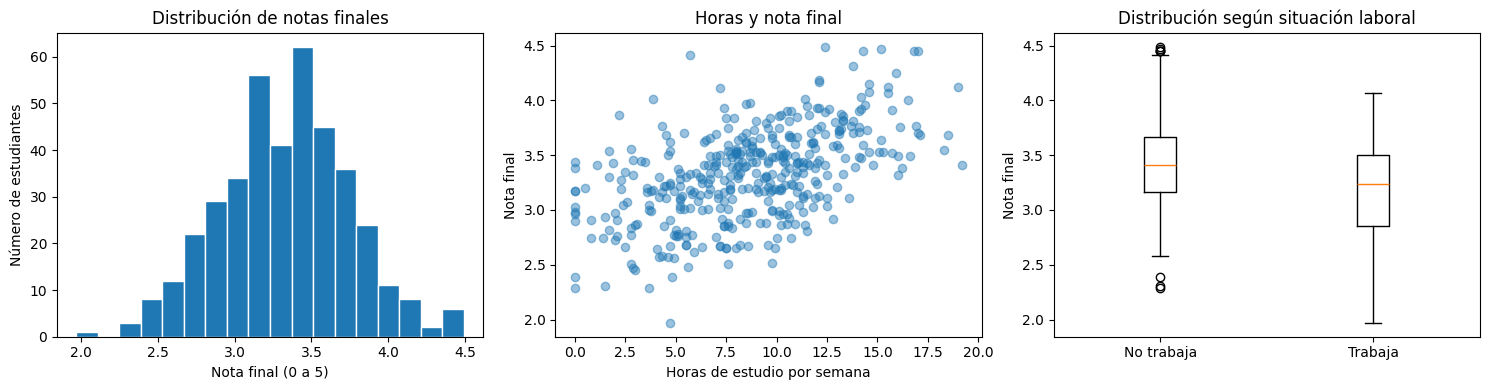

CORRELACIONES LINEALES CON NOTA FINAL (sin interpretación causal):
promedio_anterior       0.602
horas_estudio_semana    0.531
asistencia_pct          0.183
trabaja                -0.256
nota_final              1.000
Name: nota_final, dtype: float64


In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(datos.nota_final, bins=18, edgecolor='white')
ejes[0].set(title='Distribución de notas finales', xlabel='Nota final (0 a 5)', ylabel='Número de estudiantes')
ejes[1].scatter(datos.horas_estudio_semana, datos.nota_final, alpha=.45)
ejes[1].set(title='Horas y nota final', xlabel='Horas de estudio por semana', ylabel='Nota final')
ejes[2].boxplot([datos.loc[datos.trabaja==0, 'nota_final'],
                 datos.loc[datos.trabaja==1, 'nota_final']], tick_labels=['No trabaja','Trabaja'])
ejes[2].set(title='Distribución según situación laboral', ylabel='Nota final')
plt.tight_layout()
plt.show()
print('CORRELACIONES LINEALES CON NOTA FINAL (sin interpretación causal):')
print(datos.corr(numeric_only=True)['nota_final'].round(3))

### Qué significa cada elemento y el resultado `corr()`

- **Histograma:** la altura de una barra expresa cuántas notas cayeron en ese intervalo; no mide predicciones ni errores.
- **Dispersión:** cada punto es un estudiante; puntos hacia arriba conforme aumentan las horas sugieren asociación positiva. La variabilidad vertical advierte que la nota también depende de otras variables y del ruido.
- **Cajas:** la línea interna es la mediana; los bordes representan Q1 y Q3. Diferencias entre grupos describen asociaciones, no efectos causales del empleo.
- **Correlación de Pearson:** toma valores entre −1 y +1; signo positivo implica asociación lineal positiva, signo negativo asociación negativa; cerca de 0 indica poca relación **lineal bivariada**, no ausencia de cualquier tipo de relación.
- La correlación de `nota_final` consigo misma será 1: **no es un descubrimiento**.
- **No usar correlación como coeficiente de regresión:** la correlación no mantiene constantes las demás características; los coeficientes de regresión sí las incluyen en su interpretación condicional.

## 6. Definir `X` y `y`

`X` es la matriz bidimensional de **cuatro entradas**; `y` es el vector unidimensional de **400 notas finales**. `shape` devuelve dimensiones: `(400,4)` son 400 filas y 4 columnas; `(400,)` es un vector de 400 valores.

In [ ]:
caracteristicas = ['promedio_anterior','horas_estudio_semana','asistencia_pct','trabaja']
objetivo = 'nota_final'
X = datos[caracteristicas]
y = datos[objetivo]
print('Dimensiones de X:', X.shape)
print('Dimensiones de y:', y.shape)
print('Variables predictoras:', caracteristicas)
print('Variable objetivo:', objetivo)

Dimensiones de X: (400, 4)
Dimensiones de y: (400,)
Variables predictoras: ['promedio_anterior', 'horas_estudio_semana', 'asistencia_pct', 'trabaja']
Variable objetivo: nota_final


## 7. Separar entrenamiento (80 %) y prueba (20 %)

`test_size=0.20` asigna 80 de las 400 observaciones al examen de prueba y deja 320 para ajustar coeficientes. `random_state=42` hace la partición reproducible.

**Por qué:** no se deben estimar coeficientes usando las 80 notas de prueba y después declarar que se evaluó en datos desconocidos; sería contaminación de la evaluación. Un 80/20 es una elección práctica, no una norma universal.

In [ ]:
X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA)
print(f'Entrenamiento: {len(X_entrena)} estudiantes ({len(X_entrena)/len(X):.0%})')
print(f'Prueba: {len(X_prueba)} estudiantes ({len(X_prueba)/len(X):.0%})')
assert len(X_entrena)==320 and len(X_prueba)==80

Entrenamiento: 320 estudiantes (80%)
Prueba: 80 estudiantes (20%)


## 8. Entrenar la regresión lineal **múltiple**

Como tenemos cuatro entradas se trata de **regresión lineal múltiple**. `LinearRegression()` crea un estimador y `fit` calcula los coeficientes por mínimos cuadrados ordinarios. El mensaje «Entrenamiento finalizado» **no** indica que la regresión sea precisa.

\[\widehat{y}=b_0+b_1X_1+b_2X_2+b_3X_3+b_4X_4\]

Los coeficientes se estiman **solo con entrenamiento**; luego podremos medir su desempeño en prueba.

In [ ]:
modelo = LinearRegression()
modelo.fit(X_entrena, y_entrena)
print('Entrenamiento finalizado. El modelo ya tiene un intercepto y cuatro coeficientes.')

Entrenamiento finalizado. El modelo ya tiene un intercepto y cuatro coeficientes.


## 9. Interpretar el intercepto y **cada coeficiente numérico**

- **Intercepto**: nota predicha si todas las entradas valieran cero; esa combinación puede ser irreal y quedar fuera de la muestra. Un intercepto negativo no condena automáticamente al modelo.
- **Promedio anterior**: un punto más de promedio corresponde a un cambio estimado de `b1` puntos de nota, manteniendo fijas las otras entradas.
- **Horas**: una hora adicional semanal se asocia con `b2` puntos más o menos (según signo) en la predicción, manteniendo las otras variables.
- **Asistencia**: un **punto porcentual** más de asistencia (p.ej. 80 % → 81 %) se asocia con `b3` puntos de nota, no se confunde con un incremento porcentual relativo del 1 %.
- **Trabaja**: pasar de 0 (no) a 1 (sí) se asocia con una diferencia de `b4` puntos, manteniendo las demás entradas constantes.

**Advertencia:** no compare importancia de variables solo por coeficientes brutos: usan unidades distintas. No hay pruebas p ni intervalos de confianza aquí; no pueden inferirse significancias. Tampoco se demuestra causalidad.

In [ ]:
coeficientes = pd.DataFrame({'variable': caracteristicas, 'coeficiente_estimado': modelo.coef_})
print(f'INTERCEPTO = {modelo.intercept_:.4f}')
display(coeficientes.round(4))
print('\nECUACIÓN APROXIMADA DEL MODELO:')
ecuacion = f'nota_predicha = {modelo.intercept_:.4f}'
for nombre, coef in zip(caracteristicas, modelo.coef_):
    ecuacion += f' {coef:+.4f} × {nombre}'
print(ecuacion)
print('\nINTERPRETACIONES CALCULADAS:')
for nombre, b in zip(caracteristicas, modelo.coef_):
    if nombre=='trabaja':
        print(f'- Trabaja (1 frente a 0): diferencia ajustada {b:+.4f} puntos.')
    else:
        unidad = 'punto porcentual de asistencia' if nombre=='asistencia_pct' else ('hora semanal' if nombre=='horas_estudio_semana' else 'punto de promedio')
        print(f'- Cada {unidad} adicional: cambio previsto {b:+.4f} puntos de nota (todo lo demás constante).')
print(f'- Diez puntos porcentuales más de asistencia: {modelo.coef_[2]*10:+.4f} puntos de nota.')
print(f'- Cinco horas semanales adicionales: {modelo.coef_[1]*5:+.4f} puntos de nota.')

INTERCEPTO = -0.0845


,variable,coeficiente_estimado
0,promedio_anterior,0.5904
1,horas_estudio_semana,0.0609
2,asistencia_pct,0.0104
3,trabaja,-0.2601



ECUACIÓN APROXIMADA DEL MODELO:
nota_predicha = -0.0845 +0.5904 × promedio_anterior +0.0609 × horas_estudio_semana +0.0104 × asistencia_pct -0.2601 × trabaja

INTERPRETACIONES CALCULADAS:
- Cada punto de promedio adicional: cambio previsto +0.5904 puntos de nota (todo lo demás constante).
- Cada hora semanal adicional: cambio previsto +0.0609 puntos de nota (todo lo demás constante).
- Cada punto porcentual de asistencia adicional: cambio previsto +0.0104 puntos de nota (todo lo demás constante).
- Trabaja (1 frente a 0): diferencia ajustada -0.2601 puntos.
- Diez puntos porcentuales más de asistencia: +0.1037 puntos de nota.
- Cinco horas semanales adicionales: +0.3043 puntos de nota.


## 10. Comparar los coeficientes estimados con los **parámetros de simulación**

**Solo es posible aquí porque conocemos la fórmula usada para fabricar los datos.** La diferencia = `coeficiente estimado - coeficiente generador`. Un resultado distinto de cero es normal: hay ruido, muestra limitada, redondeo y acotamiento de notas.

Esta comparación **no** permite concluir que los coeficientes observados en estudiantes reales sean iguales a los programados.

In [ ]:
coeficientes_simulacion = {'promedio_anterior':0.62,'horas_estudio_semana':0.055,
                            'asistencia_pct':0.011,'trabaja':-0.22}
comparacion = pd.DataFrame({
    'variable':caracteristicas,
    'parametro_generador':[coeficientes_simulacion[v] for v in caracteristicas],
    'coeficiente_estimado':modelo.coef_
})
comparacion['diferencia']=comparacion['coeficiente_estimado']-comparacion['parametro_generador']
display(comparacion.round(4))
print('Ejemplo de lectura: diferencia positiva = el estimador quedó por encima del valor generador.')

,variable,parametro_generador,coeficiente_estimado,diferencia
0,promedio_anterior,0.620,0.5904,-0.0296
1,horas_estudio_semana,0.055,0.0609,0.0059
2,asistencia_pct,0.011,0.0104,-0.0006
3,trabaja,-0.220,-0.2601,-0.0401


Ejemplo de lectura: diferencia positiva = el estimador quedó por encima del valor generador.


## 11. Predecir los 80 estudiantes del conjunto de prueba

`predict(X_prueba)` produce 80 predicciones de nota. La tabla muestra **diez** de ellas, no el conjunto completo. Definimos aquí `error = predicha − real`:

- **Error positivo**: sobreestimación (el modelo pronostica una nota mayor).
- **Error negativo**: subestimación.
- **Error cero**: coincidencia exacta.
- **Error absoluto**: magnitud de la equivocación, independientemente del signo.

**Importante:** en el gráfico de residuos posterior usaremos `real − predicha`, el **signo contrario** al error de esta tabla. No confundas ambas convenciones.

In [ ]:
y_predicho = modelo.predict(X_prueba)
resultados = pd.DataFrame({'nota_real':y_prueba.to_numpy(), 'nota_predicha':y_predicho})
resultados['error_predicha_menos_real'] = resultados.nota_predicha-resultados.nota_real
resultados['error_absoluto'] = resultados.error_predicha_menos_real.abs()
display(resultados.head(10).round(3))
print('EXPLICACIÓN DE CADA FILA PRESENTADA:')
for i, fila in resultados.head(10).reset_index(drop=True).iterrows():
    signo = 'sobreestimó' if fila['error_predicha_menos_real']>0 else ('subestimó' if fila['error_predicha_menos_real']<0 else 'acertó exactamente')
    print(f'Caso {i+1}: nota real {fila.nota_real:.2f}, predicha {fila.nota_predicha:.2f}; '
          f'{signo}; error absoluto {fila.error_absoluto:.3f} puntos.')
print(f'\nCasos mostrados: 10 de {len(resultados)}. NO se infiere la calidad global usando solo estas diez filas.')

,nota_real,nota_predicha,error_predicha_menos_real,error_absoluto
0,3.16,3.497,0.337,0.337
1,3.93,3.792,-0.138,0.138
2,2.94,2.697,-0.243,0.243
3,3.23,3.053,-0.177,0.177
4,3.68,3.514,-0.166,0.166
5,2.67,2.939,0.269,0.269
6,2.58,2.770,0.190,0.190
7,2.51,2.561,0.051,0.051
8,3.27,2.960,-0.310,0.310
9,4.08,4.189,0.109,0.109


EXPLICACIÓN DE CADA FILA PRESENTADA:
Caso 1: nota real 3.16, predicha 3.50; sobreestimó; error absoluto 0.337 puntos.
Caso 2: nota real 3.93, predicha 3.79; subestimó; error absoluto 0.138 puntos.
Caso 3: nota real 2.94, predicha 2.70; subestimó; error absoluto 0.243 puntos.
Caso 4: nota real 3.23, predicha 3.05; subestimó; error absoluto 0.177 puntos.
Caso 5: nota real 3.68, predicha 3.51; subestimó; error absoluto 0.166 puntos.
Caso 6: nota real 2.67, predicha 2.94; sobreestimó; error absoluto 0.269 puntos.
Caso 7: nota real 2.58, predicha 2.77; sobreestimó; error absoluto 0.190 puntos.
Caso 8: nota real 2.51, predicha 2.56; sobreestimó; error absoluto 0.051 puntos.
Caso 9: nota real 3.27, predicha 2.96; subestimó; error absoluto 0.310 puntos.
Caso 10: nota real 4.08, predicha 4.19; sobreestimó; error absoluto 0.109 puntos.

Casos mostrados: 10 de 80. NO se infiere la calidad global usando solo estas diez filas.


## 12. Evaluar **MAE, RMSE y R²** con todos los 80 casos

**MAE = error absoluto medio:**
\[MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|\]
Representa el tamaño promedio de la equivocación en **puntos de nota**. No es porcentaje de aciertos.

**RMSE = raíz del error cuadrático medio:**
\[RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}\]
Da mayor peso a grandes equivocaciones; también se expresa en **puntos de nota**. Suele ser ≥ MAE.

**Coeficiente de determinación (R²):**
\[R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\overline{y}_{prueba})^2}\]
Compara la suma de errores cuadrados del modelo con la de predecir siempre la **media real de prueba**, usada solo como referencia matemática de R²; **no** se entrena con esa media. R² puede ser negativo. Por ejemplo, **R²=0,80 no significa 80 % de alumnos acertados**.

**Juicio responsable:** no existen umbrales universales («R² > 0,8 es bueno»). Interpreta las métricas en unidades, compáralas contra una estrategia básica y considera el propósito, el costo del error y datos externos.

In [ ]:
mae = mean_absolute_error(y_prueba,y_predicho)
rmse = np.sqrt(mean_squared_error(y_prueba,y_predicho))
r2 = r2_score(y_prueba,y_predicho)
print(f'MAE  = {mae:.4f} puntos de nota')
print(f'RMSE = {rmse:.4f} puntos de nota')
print(f'R²   = {r2:.4f}')
print('\nINTERPRETACIÓN AUTOMÁTICA:')
print(f'En las {len(y_prueba)} notas de prueba, el error absoluto medio fue {mae:.4f} puntos.')
print(f'La raíz del error cuadrático medio fue {rmse:.4f} puntos, penalizando más errores grandes.')
print(f'R²={r2:.4f}: reducción relativa de suma de errores cuadrados frente a la media de prueba: {r2*100:.2f} %.')
print('No representa un porcentaje de aciertos ni demuestra relaciones causales.')
if r2<0:
    print('El modelo es peor en suma de cuadrados que predecir la media de las notas de prueba.')
elif r2==1:
    print('Predicción exacta en este conjunto de prueba (comprobar posible fuga de información).')
else:
    print('Resultado que debe evaluarse frente al modelo básico y los residuos.')

MAE  = 0.1504 puntos de nota
RMSE = 0.1850 puntos de nota
R²   = 0.8110

INTERPRETACIÓN AUTOMÁTICA:
En las 80 notas de prueba, el error absoluto medio fue 0.1504 puntos.
La raíz del error cuadrático medio fue 0.1850 puntos, penalizando más errores grandes.
R²=0.8110: reducción relativa de suma de errores cuadrados frente a la media de prueba: 81.10 %.
No representa un porcentaje de aciertos ni demuestra relaciones causales.
Resultado que debe evaluarse frente al modelo básico y los residuos.


## 13. ¿Es mejor que predecir siempre la media de entrenamiento?

Un `DummyRegressor(strategy="mean")` aprende solamente la media de **entrenamiento**, y predice esa cifra constante para todos los casos de prueba. Es un punto de comparación simple.

- Si el MAE de regresión es **menor**, mejora el error absoluto medio.
- Si el R² de referencia es **negativo**, significa que ese predictor constante aprendido en entrenamiento es peor que usar la media real de prueba, utilizada en la definición de R².
- **Reducción porcentual del MAE:** \((1-MAE_{lineal}/MAE_{referencia})\times100\). No confundir con una tasa de aciertos.

In [ ]:
referencia = DummyRegressor(strategy='mean')
referencia.fit(X_entrena,y_entrena)
y_referencia = referencia.predict(X_prueba)
mae_ref=mean_absolute_error(y_prueba,y_referencia)
r2_ref=r2_score(y_prueba,y_referencia)
comparativa=pd.DataFrame({'modelo':['Predecir media del entrenamiento','Regresión lineal'],
                          'MAE':[mae_ref,mae], 'RMSE':[np.sqrt(mean_squared_error(y_prueba,y_referencia)),rmse],
                          'R2':[r2_ref,r2]})
display(comparativa.round(4))
reduccion = (1-mae/mae_ref)*100 if mae_ref>0 else np.nan
print(f'La regresión {"reduce" if reduccion>0 else "no reduce"} el MAE frente a la referencia: {reduccion:.2f} %.')
print(f'R² del predictor constante basado en entrenamiento: {r2_ref:.4f}.')
if mae<mae_ref and r2>r2_ref:
    print('VALORACIÓN: favorable en esta partición; la regresión supera la referencia en MAE y R².')
else:
    print('VALORACIÓN: revisar; la mejora frente a la referencia no es consistente en ambas métricas.')

,modelo,MAE,RMSE,R2
0,Predecir media del entrenamiento,0.3335,0.4315,-0.028
1,Regresión lineal,0.1504,0.1850,0.811


La regresión reduce el MAE frente a la referencia: 54.91 %.
R² del predictor constante basado en entrenamiento: -0.0280.
VALORACIÓN: favorable en esta partición; la regresión supera la referencia en MAE y R².


## 14. Leer las **dos gráficas diagnósticas**, punto por punto

### Izquierda: «Predicho frente a real»
- **Eje X:** nota real. **Eje Y:** nota predicha. **Cada punto:** un estudiante de prueba.
- **Diagonal punteada roja:** `predicha = real` (predicción perfecta).
- **Por encima** de la diagonal: se **sobreestima**. **Por debajo:** se **subestima**.
- **Puntos próximos** a la diagonal: menor error. Puntos muy alejados: grandes equivocaciones.

### Derecha: «Errores residuales»
- **Eje X:** nota predicha. **Eje Y:** residual = **real − predicha**.
- **Cero horizontal:** predicción exacta.
- **Residual positivo:** nota real mayor que predicha, por tanto **subestimación**.
- **Residual negativo:** nota real menor que predicha, por tanto **sobreestimación**.
- Conviene una nube sin curva ni abanico definidos, pero una inspección visual **no prueba** normalidad, independencia ni homocedasticidad.

**Muy importante:** la gráfica de residuos utiliza el signo contrario al campo `error_predicha_menos_real` de la tabla anterior.

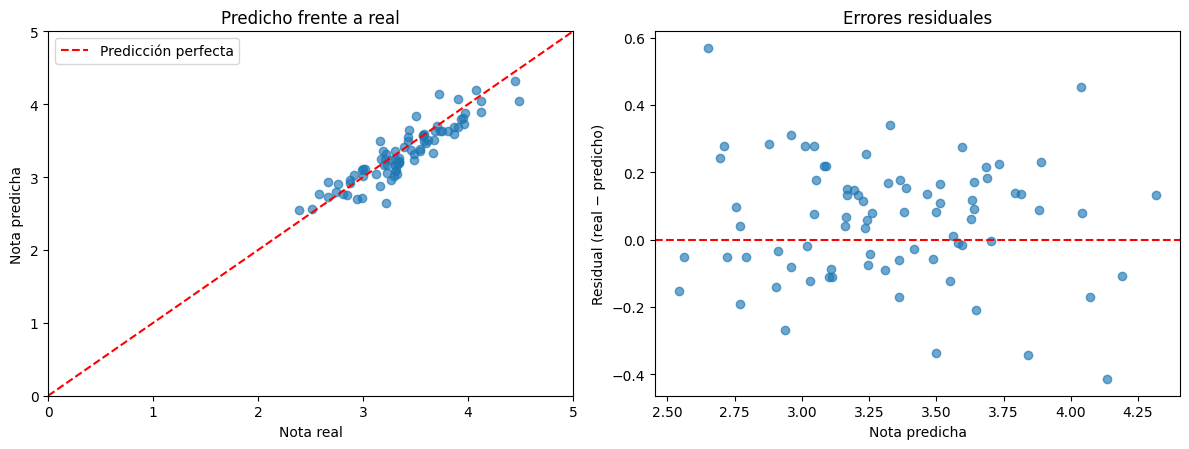

RESUMEN DE PUNTOS PARA INTERPRETAR GRÁFICAS:
Nº de puntos en cada gráfica: 80.
Menor residual: -0.415; mayor residual: +0.570.
Promedio de los residuos en prueba: +0.0570.
Errores absolutos mayores que 0.30 puntos: 7 de 80.
NOTA: describir los patrones observados, pero no declarar supuestos comprobados solo por inspección.


In [ ]:
fig, ejes = plt.subplots(1,2,figsize=(12,4.6))
ejes[0].scatter(y_prueba,y_predicho,alpha=.65)
ejes[0].plot([0,5],[0,5],'r--',label='Predicción perfecta')
ejes[0].set(xlim=(0,5),ylim=(0,5),xlabel='Nota real',ylabel='Nota predicha',title='Predicho frente a real')
ejes[0].legend()
residuales = y_prueba.to_numpy()-y_predicho
ejes[1].scatter(y_predicho,residuales,alpha=.65)
ejes[1].axhline(0,color='red',linestyle='--')
ejes[1].set(xlabel='Nota predicha',ylabel='Residual (real − predicho)',title='Errores residuales')
plt.tight_layout()
plt.show()
print('RESUMEN DE PUNTOS PARA INTERPRETAR GRÁFICAS:')
print(f'Nº de puntos en cada gráfica: {len(residuales)}.')
print(f'Menor residual: {residuales.min():+.3f}; mayor residual: {residuales.max():+.3f}.')
print(f'Promedio de los residuos en prueba: {residuales.mean():+.4f}.')
print(f'Errores absolutos mayores que 0.30 puntos: {(np.abs(residuales)>0.30).sum()} de {len(residuales)}.')
print('NOTA: describir los patrones observados, pero no declarar supuestos comprobados solo por inspección.')

## 15. Predicción de tres estudiantes nuevos: lectura de **cada número**

Creamos tres perfiles hipotéticos, con las mismas cuatro variables y unidades usadas en el ajuste. El modelo calcula una predicción para cada fila usando la ecuación ya estimada; no conoce la nota real de esos estudiantes.

**Interpretación de una predicción de 4,20, por ejemplo:** el modelo estima 4,20 sobre 5 en la configuración ingresada; **no** significa que el estudiante vaya a obtener exactamente 4,20.

Si dos perfiles difieren en más de una característica, **no atribuyas** toda la diferencia a una sola variable. Conviene cambiar solo una variable por vez para explicar el efecto algebraico del coeficiente.

In [ ]:
nuevos=pd.DataFrame({
    'promedio_anterior':[4.30,3.10,3.60],
    'horas_estudio_semana':[15.0,4.0,9.0],
    'asistencia_pct':[95.0,62.0,85.0],
    'trabaja':[0,1,1]
})[caracteristicas]
notas_nuevas=modelo.predict(nuevos)
tabla_nuevos=nuevos.copy()
tabla_nuevos.insert(0,'estudiante',[1,2,3])
tabla_nuevos['nota_predicha']=notas_nuevas
display(tabla_nuevos.round(3))
for i, nota_estimada in enumerate(notas_nuevas,1):
    fila=nuevos.iloc[i-1]
    print(f'Estudiante {i}: promedio {fila.promedio_anterior:.2f}, estudio {fila.horas_estudio_semana:.1f} h, '
          f'asistencia {fila.asistencia_pct:.1f} %, trabaja {int(fila.trabaja)}; '
          f'nota estimada {nota_estimada:.3f}.')
print('Las tres notas son predicciones; no se tienen notas reales para evaluar esos casos.')

,estudiante,promedio_anterior,horas_estudio_semana,asistencia_pct,trabaja,nota_predicha
0,1,4.3,15.0,95.0,0,4.352
1,2,3.1,4.0,62.0,1,2.372
2,3,3.6,9.0,85.0,1,3.210


Estudiante 1: promedio 4.30, estudio 15.0 h, asistencia 95.0 %, trabaja 0; nota estimada 4.352.
Estudiante 2: promedio 3.10, estudio 4.0 h, asistencia 62.0 %, trabaja 1; nota estimada 2.372.
Estudiante 3: promedio 3.60, estudio 9.0 h, asistencia 85.0 %, trabaja 1; nota estimada 3.210.
Las tres notas son predicciones; no se tienen notas reales para evaluar esos casos.


## 16. ¿Cómo reconocer un posible sobreajuste? Entrenamiento frente a prueba

Un modelo puede aprender muy bien el entrenamiento y fallar en registros nuevos. Comparamos MAE, RMSE y R² en ambos subconjuntos.

- **MAE/RMSE mucho menores en entrenamiento** que en prueba: señal para investigar sobreajuste u otros cambios entre conjuntos.
- **Resultados parecidos:** indicio favorable de estabilidad para esta partición, aunque no garantía.
- **R² alto solo en entrenamiento:** no prueba buena generalización.

**Cuidado:** ninguna única diferencia numérica es un umbral universal; depende del tamaño de muestra y de su variabilidad.

In [ ]:
pred_entrena=modelo.predict(X_entrena)
pred_prueba=modelo.predict(X_prueba)
evaluacion=pd.DataFrame({
    'Conjunto':['Entrenamiento','Prueba'],
    'Observaciones':[len(y_entrena),len(y_prueba)],
    'MAE':[mean_absolute_error(y_entrena,pred_entrena),mean_absolute_error(y_prueba,pred_prueba)],
    'RMSE':[np.sqrt(mean_squared_error(y_entrena,pred_entrena)),np.sqrt(mean_squared_error(y_prueba,pred_prueba))],
    'R2':[r2_score(y_entrena,pred_entrena),r2_score(y_prueba,pred_prueba)]
})
display(evaluacion.round(4))
print(f'Diferencia MAE (prueba menos entrenamiento): {evaluacion.MAE.iloc[1]-evaluacion.MAE.iloc[0]:+.4f} puntos.')
print('Compara ambas filas; ninguna métrica demuestra por sí sola ausencia de sobreajuste.')

,Conjunto,Observaciones,MAE,RMSE,R2
0,Entrenamiento,320,0.1377,0.1742,0.8266
1,Prueba,80,0.1504,0.1850,0.8110


Diferencia MAE (prueba menos entrenamiento): +0.0126 puntos.
Compara ambas filas; ninguna métrica demuestra por sí sola ausencia de sobreajuste.


## 17. Validación cruzada de cinco particiones

En lugar de depender de una sola división, usamos cinco rondas: en cada una se entrena con cuatro quintos del conjunto de entrenamiento y se evalúa en el quinto restante. **La prueba original de 80 registros queda aislada.**

- `cv=5`: cinco evaluaciones.
- `MAE`: menor es mejor; mostramos también su desviación entre rondas.
- `R²`: cuanto mayor, mejor respecto a predecir la media de cada subconjunto evaluado; puede ser negativo.
- Que las cinco rondas se parezcan es señal de estabilidad aproximada; **no** equivale a comprobar los supuestos estadísticos ni desempeño externo.

In [ ]:
cv=KFold(n_splits=5,shuffle=True,random_state=SEMILLA)
res_cv=cross_validate(LinearRegression(),X_entrena,y_entrena,cv=cv,
                      scoring={'mae':'neg_mean_absolute_error','r2':'r2'})
cv_tabla=pd.DataFrame({'Ronda':np.arange(1,6),
                       'MAE':-res_cv['test_mae'],'R2':res_cv['test_r2']})
display(cv_tabla.round(4))
print(f'MAE medio en validación cruzada: {cv_tabla.MAE.mean():.4f} puntos.')
print(f'Desviación estándar de los MAE de las 5 rondas: {cv_tabla.MAE.std():.4f} puntos.')
print(f'R² medio de validación cruzada: {cv_tabla.R2.mean():.4f}.')
print('Los 80 registros del conjunto de prueba no participaron en estas cinco evaluaciones.')

,Ronda,MAE,R2
0,1,0.1430,0.8225
1,2,0.1302,0.8485
2,3,0.1387,0.7803
3,4,0.1587,0.8239
4,5,0.1296,0.8126


MAE medio en validación cruzada: 0.1400 puntos.
Desviación estándar de los MAE de las 5 rondas: 0.0119 puntos.
R² medio de validación cruzada: 0.8176.
Los 80 registros del conjunto de prueba no participaron en estas cinco evaluaciones.


## 18. Análisis más detallado de los residuos y límites de predicción

La distribución de residuos ayuda a detectar asimetrías y errores grandes. El gráfico residual frente a horas de estudio permite explorar tendencias que podrían pasar desapercibidas si solo se graficaran contra predicciones.

Un histograma aproximadamente simétrico **no prueba** normalidad; un diagrama sin embudo **no prueba** varianza constante. También se necesita conocer el diseño de muestreo para estudiar independencia.

**Notas fuera del rango [0, 5]:** la regresión lineal ordinaria puede producir valores fuera del rango permitido al recibir perfiles extremos o nunca observados. No confundas esas posibles predicciones con datos reales.

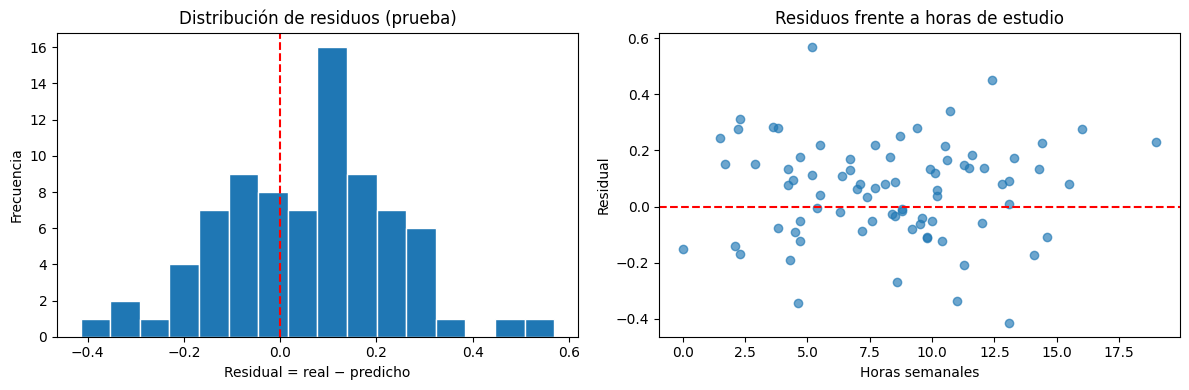

Residuo medio: +0.0570; desviación estándar de residuos: 0.1771.
Predicciones fuera de [0,5] entre los 80 casos de prueba: 0.
La ausencia de predicciones fuera de rango en esta prueba NO impide que ocurran con nuevos datos.


In [ ]:
fig, ejes=plt.subplots(1,2,figsize=(12,4))
ejes[0].hist(residuales,bins=16,edgecolor='white')
ejes[0].axvline(0,color='red',linestyle='--')
ejes[0].set(title='Distribución de residuos (prueba)',xlabel='Residual = real − predicho',ylabel='Frecuencia')
ejes[1].scatter(X_prueba.horas_estudio_semana,residuales,alpha=.65)
ejes[1].axhline(0,color='red',linestyle='--')
ejes[1].set(title='Residuos frente a horas de estudio',xlabel='Horas semanales',ylabel='Residual')
plt.tight_layout();plt.show()
print(f'Residuo medio: {residuales.mean():+.4f}; desviación estándar de residuos: {np.std(residuales,ddof=1):.4f}.')
print(f'Predicciones fuera de [0,5] entre los 80 casos de prueba: {int(((y_predicho<0)|(y_predicho>5)).sum())}.')
print('La ausencia de predicciones fuera de rango en esta prueba NO impide que ocurran con nuevos datos.')

## 19. Conclusión **automática** basada en los resultados calculados

El siguiente resumen incluye la cantidad de registros, MAE, RMSE, R², comparación frente al modelo básico y validación cruzada, sin copiar valores de una ejecución anterior. Es importante mantener la conclusión circunscrita a **datos ficticios** y a **desempeño predictivo**, no causal.

In [ ]:
print('=== CONCLUSIÓN DOCENTE DEL EXPERIMENTO ===')
print(f'La base sintética contiene {len(datos)} observaciones y {len(caracteristicas)} predictores.')
print(f'Se entrenó con {len(X_entrena)} casos y se evaluó con {len(X_prueba)} casos reservados.')
print(f'En prueba: MAE={mae:.3f} puntos, RMSE={rmse:.3f} puntos y R²={r2:.3f}.')
print(f'Frente a predecir la media de entrenamiento (MAE={mae_ref:.3f}), '
      f'el cambio relativo en MAE fue {reduccion:.1f} %.')
print(f'La validación cruzada dentro del entrenamiento obtuvo MAE medio={cv_tabla.MAE.mean():.3f} '
      f'y R² medio={cv_tabla.R2.mean():.3f}.')
if (mae < mae_ref) and (r2 > 0):
    print('Juicio: desempeño favorable frente a la referencia para este ejercicio sintético.')
else:
    print('Juicio: el modelo requiere revisión; no hay mejora clara frente a la referencia.')
print('Limitaciones: datos simulados, una sola muestra de prueba; no se verificaron todos los '
      'supuestos estadísticos ni la aplicabilidad a estudiantes reales.')

=== CONCLUSIÓN DOCENTE DEL EXPERIMENTO ===
La base sintética contiene 400 observaciones y 4 predictores.
Se entrenó con 320 casos y se evaluó con 80 casos reservados.
En prueba: MAE=0.150 puntos, RMSE=0.185 puntos y R²=0.811.
Frente a predecir la media de entrenamiento (MAE=0.333), el cambio relativo en MAE fue 54.9 %.
La validación cruzada dentro del entrenamiento obtuvo MAE medio=0.140 y R² medio=0.818.
Juicio: desempeño favorable frente a la referencia para este ejercicio sintético.
Limitaciones: datos simulados, una sola muestra de prueba; no se verificaron todos los supuestos estadísticos ni la aplicabilidad a estudiantes reales.


## Referencias bibliográficas (APA 7)

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0

Montgomery, D. C., Peck, E. A., & Vining, G. G. (2021). *Introduction to linear regression analysis* (6th ed.). Wiley. https://www.wiley.com/en-us/Introduction+to+Linear+Regression+Analysis%2C+6th+Edition-p-9781119578727

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://www.jmlr.org/papers/v12/pedregosa11a.html

scikit-learn developers. (s. f.). *LinearRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

**Origen de los datos:** generados con NumPy dentro de este notebook, exclusivamente con fines didácticos. No corresponden a una investigación empírica.